In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [2]:
from google.colab import files
uploaded = files.upload()

Saving BlinkIT Grocery Data.xlsx to BlinkIT Grocery Data.xlsx


In [3]:
df=pd.read_excel('BlinkIT Grocery Data.xlsx')

In [4]:
df = pd.read_excel('/content/BlinkIT Grocery Data.xlsx')

In [5]:
display(df.head())

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [6]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')

In [7]:
print("Unique Product Categories/Types:")


Unique Product Categories/Types:


In [8]:
print(df['Item Type'].value_counts())

Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64


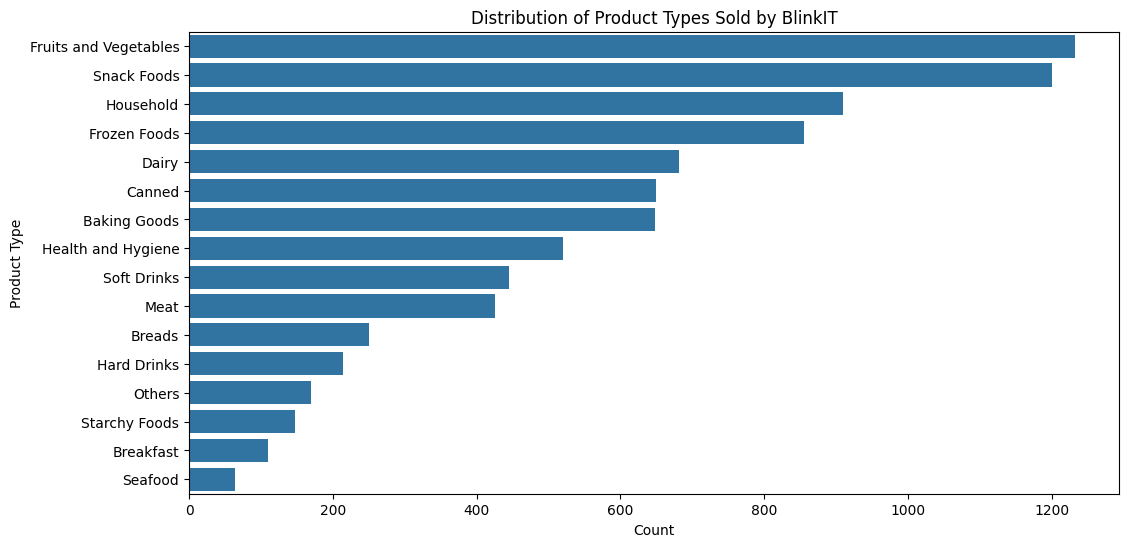

In [9]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='Item Type', order=df['Item Type'].value_counts().index)
plt.title("Distribution of Product Types Sold by BlinkIT")
plt.xlabel("Count")
plt.ylabel("Product Type")
plt.show()

# This analysis breaks down the diversity of BlinkIT’s product catalog. It identifies which product categories (e.g., **Fruits** & Vegetables, Snack Foods, Dairy) have the highest number of inventory listings, helping management understand where inventory volume is concentrated.

In [10]:
print("Outlet Types:")
print(df['Outlet Type'].value_counts())

Outlet Types:
Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64


/tmp/ipykernel_2668/2172294555.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Outlet Type', ax=axes[0], palette='viridis')
/tmp/ipykernel_2668/2172294555.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Outlet Location Type', ax=axes[1], palette='coolwarm')


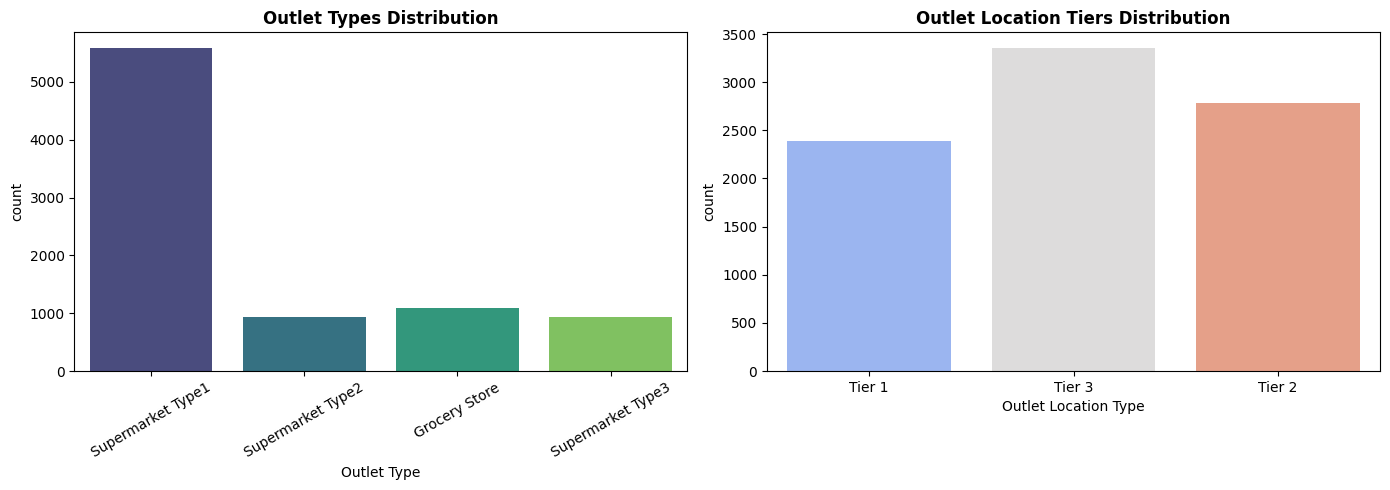

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='Outlet Type', ax=axes[0], palette='viridis')
axes[0].set_title('Outlet Types Distribution', fontweight='bold')
axes[0].tick_params(axis='x', rotation=30)
sns.countplot(data=df, x='Outlet Location Type', ax=axes[1], palette='coolwarm')
axes[1].set_title('Outlet Location Tiers Distribution', fontweight='bold')
plt.tight_layout()
plt.show()

Breaks down store footprint across operational models (e.g., Supermarket Type 1, Type 2, Grocery Store) and geographical location tiers (Tier 1, Tier 2, Tier 3). It highlights where BlinkIT's physical distribution network is concentrated.

In [12]:
total_sales = df['Sales'].sum()
avg_sales = df['Sales'].mean()
median_sales = df['Sales'].median()

print("--- OVERALL SALES METRICS ---")
print(f"Total Sales Generated : ₹{total_sales:,.2f}")
print(f"Average Sales per Item : ₹{avg_sales:,.2f}")
print(f"Median Sales per Item  : ₹{median_sales:,.2f}")

--- OVERALL SALES METRICS ---
Total Sales Generated : ₹1,201,681.49
Average Sales per Item : ₹140.99
Median Sales per Item  : ₹143.01


Summarizes gross sales revenue alongside average (mean) and median sales per item/outlet. The comparison between mean and median helps identify whether extreme sales values skew overall revenue figures

--- CUSTOMER RATING SUMMARY ---
count    8523.000000
mean        3.965857
std         0.605651
min         1.000000
25%         4.000000
50%         4.000000
75%         4.200000
max         5.000000
Name: Rating, dtype: float64


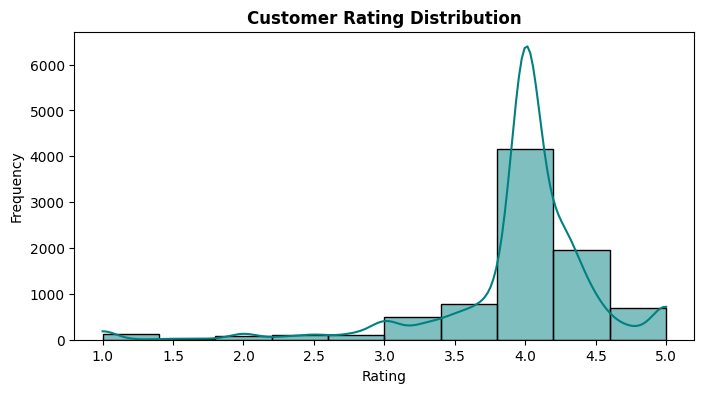

In [13]:
print("--- CUSTOMER RATING SUMMARY ---")
print(df['Rating'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df['Rating'], kde=True, color='teal', bins=10)
plt.title("Customer Rating Distribution", fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

Analyzes customer satisfaction distribution across products. Skewness or variation in ratings highlights whether customer experience is uniform or if specific product lines require quality adjustments.


In [14]:
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({'Missing Count': missing_data, 'Percentage (%)': missing_percent})
print("--- MISSING VALUES SUMMARY ---")
print(missing_df[missing_df['Missing Count'] > 0])

--- MISSING VALUES SUMMARY ---
             Missing Count  Percentage (%)
Item Weight           1463       17.165317


Detects data gaps (such as unrecorded item weights or outlet sizes). Identifying missing records prevents biased or inaccurate conclusions during downstream analysis


In [15]:
duplicates = df.duplicated().sum()
print(f"Total Duplicate Rows Found: {duplicates}")

if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed successfully!")

Total Duplicate Rows Found: 0


Flags repeated transaction records to prevent double-counting. Removing duplicate entries ensures sales performance metrics remain accurate

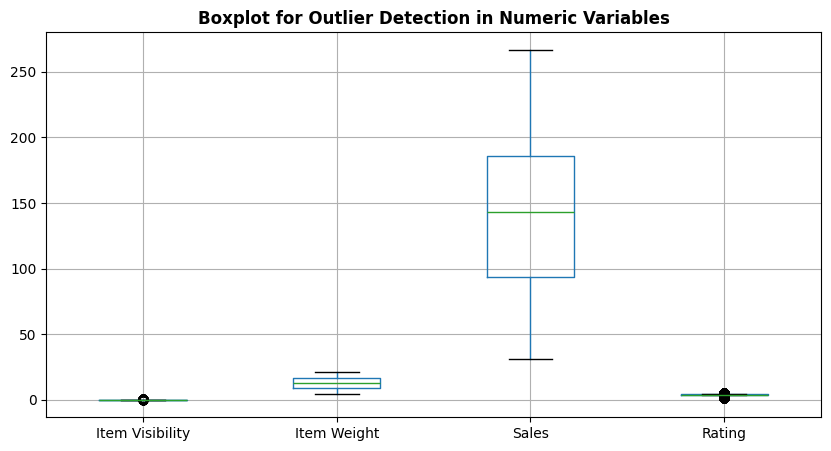

In [16]:
numeric_cols = ['Item Visibility', 'Item Weight', 'Sales', 'Rating']

plt.figure(figsize=(10, 5))
df[numeric_cols].boxplot()
plt.title("Boxplot for Outlier Detection in Numeric Variables", fontweight='bold')
plt.show()

Uses boxplots to pinpoint unusually high or low numeric values (e.g., extreme visibility levels or sales figures). This helps differentiate genuine top-performing products from potential data logging errors

In [17]:
print("Before Cleaning Item Fat Content:", df['Item Fat Content'].unique())
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

print("After Cleaning Item Fat Content:", df['Item Fat Content'].unique())

df['Item Weight'].fillna(df['Item Weight'].mean(), inplace=True)
df['Outlet Size'].fillna(df['Outlet Size'].mode()[0], inplace=True)

print("\nData cleaning & standardization complete!")

Before Cleaning Item Fat Content: ['Regular' 'Low Fat' 'low fat' 'LF' 'reg']
After Cleaning Item Fat Content: ['Regular' 'Low Fat']

Data cleaning & standardization complete!


/tmp/ipykernel_2668/1998479553.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Item Weight'].fillna(df['Item Weight'].mean(), inplace=True)
/tmp/ipykernel_2668/1998479553.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, in

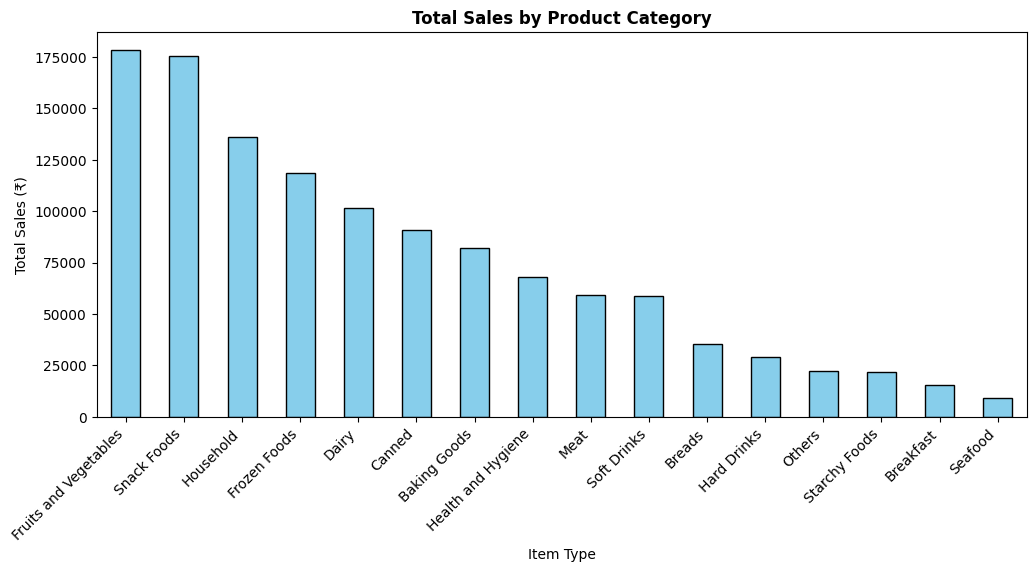

In [18]:
sales_by_product = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sales_by_product.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Total Sales by Product Category", fontweight='bold')
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45, ha='right')
plt.show()

Ranks product categories by total sales contribution. This indicates primary revenue drivers and guides demand forecasting and shelf-space allocation.

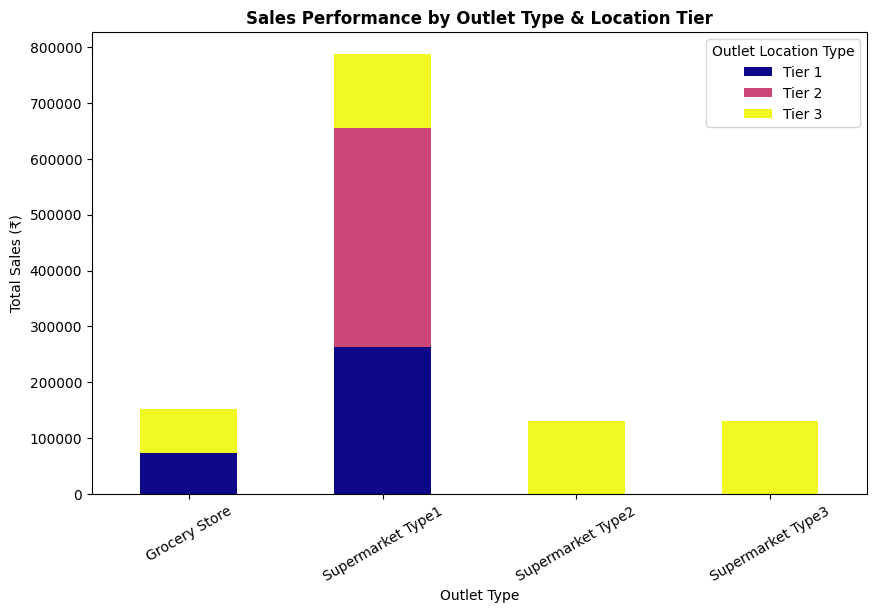

In [19]:
outlet_perf = df.groupby(['Outlet Type', 'Outlet Location Type'])['Sales'].sum().unstack()

outlet_perf.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='plasma')
plt.title("Sales Performance by Outlet Type & Location Tier", fontweight='bold')
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=30)
plt.show()

Evaluates revenue performance across store formats and location tiers. It pinpoints high-performing combinations (e.g., Tier 1 Supermarkets) to inform future expansion strategies.

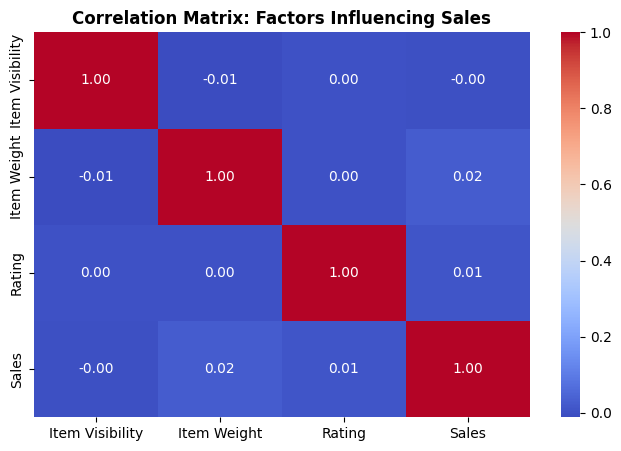

In [20]:
plt.figure(figsize=(8, 5))
sns.heatmap(df[['Item Visibility', 'Item Weight', 'Rating', 'Sales']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix: Factors Influencing Sales", fontweight='bold')
plt.show()


Measures linear relationships between numerical variables (item visibility, weight, ratings) and sales. It pinpoints key operational levers that directly drive higher transaction values.

In [21]:
p90 = df['Sales'].quantile(0.90)
p10 = df['Sales'].quantile(0.10)

top_performers = df[df['Sales'] >= p90]
low_performers = df[df['Sales'] <= p10]

print("--- TOP 10% PERFORMERS (HIGH SALES) ---")
print(top_performers[['Item Visibility', 'Item Weight', 'Rating', 'Sales']].describe())

print("\n--- BOTTOM 10% PERFORMERS (LOW SALES) ---")
print(low_performers[['Item Visibility', 'Item Weight', 'Rating', 'Sales']].describe())

--- TOP 10% PERFORMERS (HIGH SALES) ---
       Item Visibility  Item Weight      Rating       Sales
count       853.000000   853.000000  853.000000  853.000000
mean          0.065799    12.953368    3.985111  249.734937
std           0.048909     4.176164    0.560266   10.351280
min           0.000000     4.615000    1.000000  231.201000
25%           0.026913     9.895000    4.000000  240.753800
50%           0.059557    12.857645    4.000000  250.772400
75%           0.089777    16.000000    4.200000  258.564600
max           0.325781    21.350000    5.000000  266.888400

--- BOTTOM 10% PERFORMERS (LOW SALES) ---
       Item Visibility  Item Weight      Rating       Sales
count       854.000000   854.000000  854.000000  854.000000
mean          0.068982    12.850505    3.947190   42.601377
std           0.054654     3.973582    0.664692    5.567766
min           0.000000     4.880000    1.000000   31.290000
25%           0.028878     9.600000    4.000000   37.882200
50%           0.0

Contrasts top-performing items against underperforming ones. Examining differences in pricing, display visibility, and customer ratings isolates root causes of low sales performance.

In [22]:
prod_sales = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False).reset_index()
prod_sales['Cumulative Sales'] = prod_sales['Sales'].cumsum()
prod_sales['Contribution %'] = (prod_sales['Cumulative Sales'] / prod_sales['Sales'].sum()) * 100

print("--- PRODUCT CONTRIBUTION TO SALES ---")
print(prod_sales[['Item Type', 'Sales', 'Contribution %']])

--- PRODUCT CONTRIBUTION TO SALES ---
                Item Type        Sales  Contribution %
0   Fruits and Vegetables  178124.0810       14.822903
1             Snack Foods  175433.9224       29.421940
2               Household  135976.5254       40.737461
3            Frozen Foods  118558.8814       50.603543
4                   Dairy  101276.4616       59.031439
5                  Canned   90706.7290       66.579756
6            Baking Goods   81894.7364       73.394767
7      Health and Hygiene   68025.8388       79.055655
8                    Meat   59449.8638       84.002878
9             Soft Drinks   58514.1670       88.872236
10                 Breads   35379.1198       91.816370
11            Hard Drinks   29334.6806       94.257506
12                 Others   22451.8916       96.125879
13          Starchy Foods   21880.0274       97.946663
14              Breakfast   15596.6966       99.244569
15                Seafood    9077.8700      100.000000


Computes cumulative sales percentages to identify core revenue-generating categories (applying the 80/20 principle). This allows management to prioritize marketing budgets and stock availability for high-impact items

In [28]:
outlet_summary = df.groupby('Outlet Identifier').agg({
    'Sales': 'sum',
    'Rating': 'mean',
    'Outlet Type': 'first',
    'Outlet Location Type': 'first'
}).sort_values(by='Sales', ascending=False)

print("TOP 5 OUTLETS BY TOTAL SALES")
print(outlet_summary.head(5))


TOP 5 OUTLETS BY TOTAL SALES
                         Sales    Rating        Outlet Type  \
Outlet Identifier                                             
OUT035             133103.9070  3.944516  Supermarket Type1   
OUT046             132113.3698  3.958387  Supermarket Type1   
OUT013             131809.0156  3.949571  Supermarket Type1   
OUT018             131477.7764  3.971228  Supermarket Type2   
OUT045             130942.7802  3.959957  Supermarket Type1   

                  Outlet Location Type  
Outlet Identifier                       
OUT035                          Tier 2  
OUT046                          Tier 1  
OUT013                          Tier 3  
OUT018                          Tier 3  
OUT045                          Tier 2  


Ranks individual outlets based on sales output and customer ratings. Top-performing store practices can be documented and replicated across underperforming outlets

In [24]:
zero_visibility_items = df[df['Item Visibility'] == 0]
low_sales_outlets = df.groupby('Outlet Identifier')['Sales'].sum().sort_values().head(3)

print(f"Products with 0 Visibility (Need Display Fix): {len(zero_visibility_items)}")
print("\nLowest Performing Outlets (Need Management Focus):")
print(low_sales_outlets)

Products with 0 Visibility (Need Display Fix): 526

Lowest Performing Outlets (Need Management Focus):
Outlet Identifier
OUT019     73807.5824
OUT010     78131.5666
OUT017    129103.9604
Name: Sales, dtype: float64


Flags items with zero visibility on digital storefronts and identifies low-revenue outlets. Fixing app display indexing issues provides immediate opportunities for sales uplift

In [27]:
top_item = prod_sales.iloc[0]['Item Type']
top_outlet = outlet_summary.index[0]

print("STRATEGIC BUSINESS RECOMMENDATIONS")
print(f"1. Inventory Priority : Reallocate supply towards top selling category '{top_item}'.")
print(f"2. Display & Placement: Fix {len(zero_visibility_items)} products having 0 visibility in digital storefronts.")
print(f"3. Outlet Strategy    : Analyze and replicate operational practices of top outlet '{top_outlet}'.")

STRATEGIC BUSINESS RECOMMENDATIONS
1. Inventory Priority : Reallocate supply towards top selling category 'Fruits and Vegetables'.
2. Display & Placement: Fix 526 products having 0 visibility in digital storefronts.
3. Outlet Strategy    : Analyze and replicate operational practices of top outlet 'OUT035'.


Translates analytical findings into clear, actionable executive guidance regarding inventory management, digital shelf placement, and store operations